<a href="https://colab.research.google.com/github/uzmaa29/Pneumonia-Detection/blob/main/pneumonia_cnn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os
os.environ['KAGGLE_CONFIG_DIR'] = '/content'

In [ ]:
!kaggle datasets download -d paultimothymooney/chest-xray-pneumonia -p /content

Dataset URL: https://www.kaggle.com/datasets/paultimothymooney/chest-xray-pneumonia
License(s): other
chest-xray-pneumonia.zip: Skipping, found more recently modified local copy (use --force to force download)


In [ ]:
!unzip -q -o /content/chest-xray-pneumonia.zip -d /content/chest-xray-pneumonia

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (Dense, Conv2D, MaxPooling2D, Dropout,
                                     BatchNormalization, Flatten)
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import (EarlyStopping, ModelCheckpoint,
                                        ReduceLROnPlateau)
from sklearn.metrics import confusion_matrix, classification_report

SEED = 67
IMG_SIZE = (224, 224)
BATCH = 32
tf.random.set_seed(SEED)
np.random.seed(SEED)

BASE = '/content/chest-xray-pneumonia/chest_xray'
TRAIN_DIR = f'{BASE}/train'
TEST_DIR = f'{BASE}/test'

In [ ]:
import glob
import re
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit

def patient_id(path):
    name = os.path.basename(path)
    m = re.match(r'(IM-\d{4})', name) or re.match(r'(person\d+)', name)
    return m.group(1) if m else name

rows = []
for label in ['NORMAL', 'PNEUMONIA']:
    for p in glob.glob(f'{TRAIN_DIR}/{label}/*'):
        rows.append({'filepath': p, 'label': label, 'patient': patient_id(p)})
df = pd.DataFrame(rows)

print('Images:', len(df), '| Patients:', df['patient'].nunique())

Images: 5216 | Patients: 2897


In [ ]:
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
tr_idx, va_idx = next(gss.split(df, groups=df['patient']))
train_df = df.iloc[tr_idx].reset_index(drop=True)
val_df = df.iloc[va_idx].reset_index(drop=True)

shared = set(train_df['patient']) & set(val_df['patient'])
print('Patients shared between train and val:', len(shared))  # must be 0

Patients shared between train and val: 0


In [ ]:
train_datagen = ImageDataGenerator(
    rescale=1. / 255,
    rotation_range=5,
    zoom_range=0.1,
    horizontal_flip=True,
)
eval_datagen = ImageDataGenerator(rescale=1. / 255)

train_gen = train_datagen.flow_from_dataframe(
    train_df, x_col='filepath', y_col='label', target_size=IMG_SIZE,
    batch_size=BATCH, class_mode='binary', shuffle=True, seed=SEED)

val_gen = eval_datagen.flow_from_dataframe(
    val_df, x_col='filepath', y_col='label', target_size=IMG_SIZE,
    batch_size=BATCH, class_mode='binary', shuffle=False)

test_gen = eval_datagen.flow_from_directory(
    TEST_DIR, target_size=IMG_SIZE, batch_size=BATCH,
    class_mode='binary', shuffle=False)

print(train_gen.class_indices)  # NORMAL = 0, PNEUMONIA = 1
print('Train:', train_gen.samples, 'Val:', val_gen.samples,
      'Test:', test_gen.samples)


Found 4163 validated image filenames belonging to 2 classes.
Found 1053 validated image filenames belonging to 2 classes.
Found 624 images belonging to 2 classes.
{'NORMAL': 0, 'PNEUMONIA': 1}
Train: 4163 Val: 1053 Test: 624


In [ ]:
counts = np.bincount(train_gen.classes)
total = counts.sum()
class_weight = {0: total / (2 * counts[0]), 1: total / (2 * counts[1])}
print('Counts:', counts)
print('class weights', class_weight)

Counts: [1096 3067]
class weights {0: np.float64(1.8991788321167884), 1: np.float64(0.6786762308444734)}


In [ ]:
model = Sequential([
    Conv2D(32, (3, 3), activation='relu', input_shape=(224, 224, 3)),
    BatchNormalization(),
    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), activation='relu'),
    BatchNormalization(),
    MaxPooling2D((2, 2)),

    Conv2D(128, (3, 3), activation='relu'),
    BatchNormalization(),
    MaxPooling2D((2, 2)),

    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.5),
    Dense(1, activation='sigmoid'),
])


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='binary_crossentropy',
    metrics=[
        'accuracy',
        tf.keras.metrics.AUC(name='auc'),
        tf.keras.metrics.Precision(name='precision'),
        tf.keras.metrics.Recall(name='recall'),
    ],
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 222, 222, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 109, 109, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 52, 52, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,169,985 (42.61 MB)

 Trainable params: 11,169,537 (42.61 MB)

 Non-trainable params: 448 (1.75 KB)

In [ ]:
callbacks = [EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True),
             ModelCheckpoint('/content/best_model.keras', monitor='val_loss', save_best_only=True),
             ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2)]
#

In [ ]:
history = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=30,
    callbacks=callbacks,
    class_weight=class_weight
)

Epoch 1/30
131/131 ━━━━━━━━━━━━━━━━━━━━ 149s 1s/step - accuracy: 0.8612 - auc: 0.9163 - loss: 1.0762 - precision: 0.9440 - recall: 0.8627 - val_accuracy: 0.7673 - val_auc: 0.5000 - val_loss: 24.0894 - val_precision: 0.7673 - val_recall: 1.0000 - learning_rate: 0.0010
Epoch 2/30
131/131 ━━━━━━━━━━━━━━━━━━━━ 118s 903ms/step - accuracy: 0.8801 - auc: 0.9496 - loss: 0.3363 - precision: 0.9728 - recall: 0.8614 - val_accuracy: 0.7673 - val_auc: 0.5000 - val_loss: 22.4936 - val_precision: 0.7673 - val_recall: 1.0000 - learning_rate: 0.0010
Epoch 3/30
131/131 ━━━━━━━━━━━━━━━━━━━━ 113s 866ms/step - accuracy: 0.8900 - auc: 0.9603 - loss: 0.2759 - precision: 0.9759 - recall: 0.8722 - val_accuracy: 0.7673 - val_auc: 0.5429 - val_loss: 3.8498 - val_precision: 0.7673 - val_recall: 1.0000 - learning_rate: 0.0010
Epoch 4/30
131/131 ━━━━━━━━━━━━━━━━━━━━ 113s 866ms/step - accuracy: 0.8859 - auc: 0.9637 - loss: 0.2674 - precision: 0.9821 - recall: 0.8608 - val_accuracy: 0.6163 - val_auc: 0.8712 - val_los

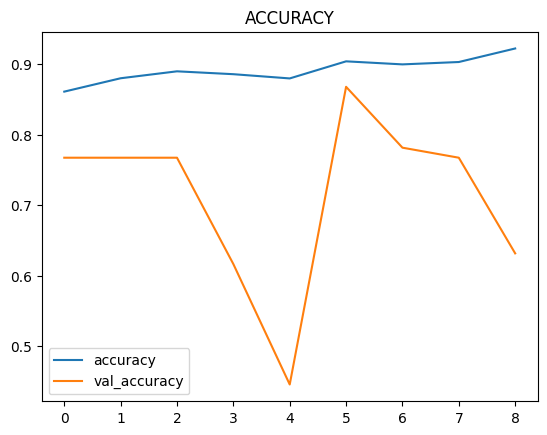

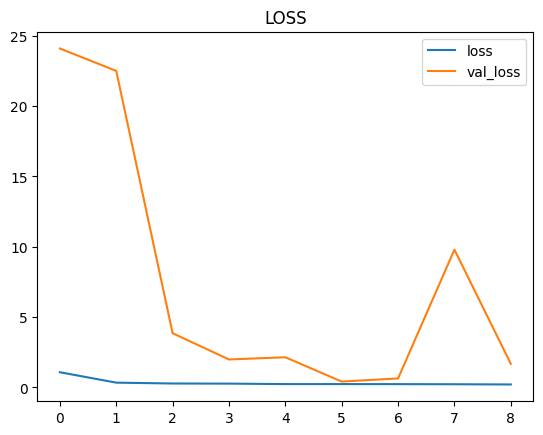

In [ ]:
hist = pd.DataFrame(history.history)
hist[['accuracy', 'val_accuracy']].plot(title='ACCURACY')
hist[['loss', 'val_loss']].plot(title='LOSS')
plt.show()

evaluation (test set)


In [ ]:
results = model.evaluate(test_gen, return_dict=True)
print(results)

20/20 ━━━━━━━━━━━━━━━━━━━━ 10s 505ms/step - accuracy: 0.8654 - auc: 0.9252 - loss: 0.4793 - precision: 0.9250 - recall: 0.8538
{'accuracy': 0.8653846383094788, 'auc': 0.9251918792724609, 'loss': 0.479289174079895, 'precision': 0.925000011920929, 'recall': 0.8538461327552795}


In [ ]:
y_prob = model.predict(test_gen).ravel()
y_true = test_gen.classes
y_pred = (y_prob > 0.5).astype(int)

20/20 ━━━━━━━━━━━━━━━━━━━━ 8s 357ms/step


In [ ]:
print(confusion_matrix(y_true, y_pred))
print(classification_report(y_true, y_pred, target_names=['NORMAL', 'PNEUMONIA']))

[[207  27]
 [ 57 333]]
              precision    recall  f1-score   support

      NORMAL       0.78      0.88      0.83       234
   PNEUMONIA       0.93      0.85      0.89       390

    accuracy                           0.87       624
   macro avg       0.85      0.87      0.86       624
weighted avg       0.87      0.87      0.87       624



In [ ]:
model.save('/content/pneumonia_cnn.keras')
from google.colab import files
files.download('/content/pneumonia_cnn.keras')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>